# Tutorial 06b — GMM, PCA and an autoencoder for traffic profiles

The original WebTRIS table contains 30 days of 15-minute traffic counts from one detector near Heathrow. A Gaussian mixture first reveals low-, medium- and high-flow regimes directly in the observed counts. We then convert the series into four-hour windows: PCA provides a linear two-dimensional representation, while a small autoencoder learns a nonlinear representation and reconstructs each window.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `06 Unsupervised learning`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [ ]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "06 Unsupervised learning"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics. PyTorch builds the neural networks used in this lesson.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [ ]:
%pip install numpy pandas matplotlib scikit-learn torch


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
COLORS = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})
torch.manual_seed(42)
np.random.seed(42)

raw = pd.read_csv("Traffic_Flow_Data.csv")
times = raw.columns[1:-1]
values = raw[times].to_numpy(dtype=float)
dates = pd.to_datetime(raw["Report Date"])

print("Raw traffic table:", values.shape, "= (days, 15-minute intervals)")
print("Values are observed vehicles per 15 minutes; the first columns are shown below.")
display(raw.iloc[:3, :8])

interval = np.arange(values.shape[1])
is_weekend = dates.dt.dayofweek >= 5
weekday_mean = values[~is_weekend].mean(axis=0)
weekend_mean = values[is_weekend].mean(axis=0)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(interval, weekday_mean, label="weekday", color=COLORS[0], linewidth=2.4)
ax.plot(interval, weekend_mean, label="weekend", color=COLORS[1], linewidth=2.4)
ax.set_xticks(interval[::8], times[::8], rotation=45)
ax.set_xlabel("time of day")
ax.set_ylabel("mean vehicles per 15 minutes")
ax.set_title("Mean daily traffic profile")
ax.legend(frameon=False)
ax.grid(alpha=0.18)
plt.tight_layout()

## Three traffic regimes with a Gaussian mixture

![WebTRIS detector context](img/Loc_Detector.png)

A histogram shows that one normal distribution is not enough: overnight, transitional and busy periods create three modes. A three-component GMM represents the observed density as a weighted sum of three Gaussian curves.

,regime,mean flow,standard deviation,mixture weight
0,low,143.557,53.695,0.189
1,medium,588.756,237.993,0.245
2,high,1077.293,116.061,0.566


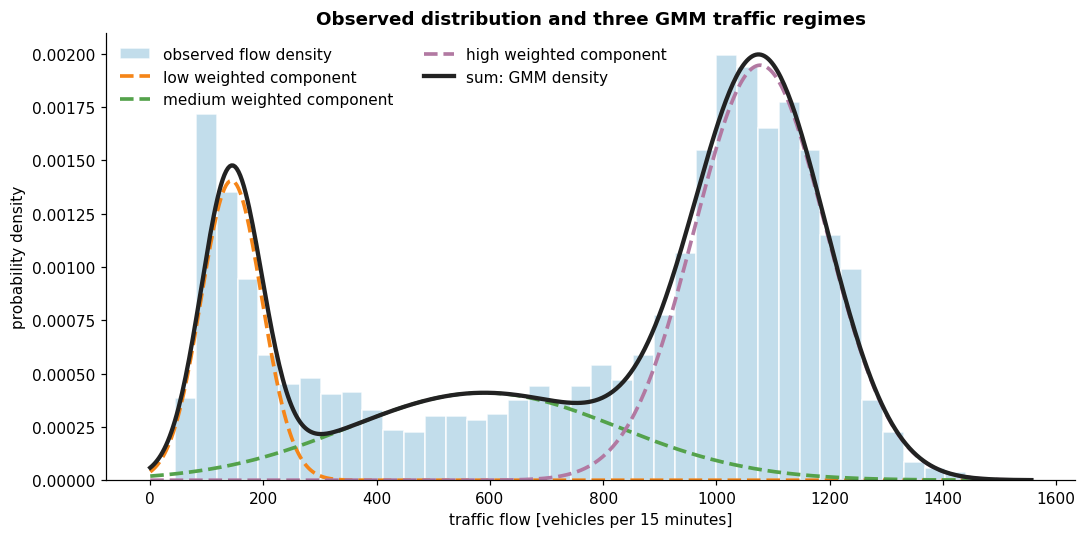

In [2]:
flow_values = values.reshape(-1, 1)
gmm = GaussianMixture(
    n_components=3,
    n_init=20,
    random_state=42,
).fit(flow_values)

# Sort the arbitrary component labels from low flow to high flow.
component_order = np.argsort(gmm.means_.ravel())
means = gmm.means_.ravel()[component_order]
standard_deviations = np.sqrt(gmm.covariances_.reshape(-1))[component_order]
weights = gmm.weights_[component_order]

regimes = pd.DataFrame({
    "regime": ["low", "medium", "high"],
    "mean flow": means,
    "standard deviation": standard_deviations,
    "mixture weight": weights,
})
display(regimes.round(3))

flow_grid = np.linspace(0, flow_values.max() * 1.08, 500)
mixture_density = np.zeros_like(flow_grid)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
    flow_values.ravel(),
    bins=38,
    density=True,
    color="#B8D8E8",
    edgecolor="white",
    alpha=0.85,
    label="observed flow density",
)

for name, mean_flow, std_flow, weight, color in zip(
    regimes["regime"], means, standard_deviations, weights, COLORS[1:]
):
    component_density = weight * np.exp(
        -0.5 * ((flow_grid - mean_flow) / std_flow) ** 2
    ) / (std_flow * np.sqrt(2 * np.pi))
    mixture_density += component_density
    ax.plot(
        flow_grid,
        component_density,
        linestyle="--",
        linewidth=2.4,
        color=color,
        label=f"{name} weighted component",
    )

ax.plot(flow_grid, mixture_density, color="#222222", linewidth=2.8, label="sum: GMM density")
ax.set_xlabel("traffic flow [vehicles per 15 minutes]")
ax.set_ylabel("probability density")
ax.set_title("Observed distribution and three GMM traffic regimes")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()

## Sliding windows, chronological split and PCA

A 16-step window covers four hours. Each window is one unlabeled input vector $\mathbf{x}\in\mathbb{R}^{16}$; there is no response variable $y$. The windows remain chronological, and the scaler is fitted on training windows only.

PCA learns two linear directions from the training windows. It compresses each window to

$$\mathbf{z}=\mathrm{PCA}(\mathbf{x})\in\mathbb{R}^{2},$$

then reconstructs it as $\hat{\mathbf{x}}=\mathrm{PCA}^{-1}(\mathbf{z})$. The reconstruction MAE compares the original four-hour profile $\mathbf{x}$ with its reconstructed profile $\hat{\mathbf{x}}$. Validation error can guide the number of components; after that choice is frozen, test reconstruction error measures how well the compressed representation generalises to unseen windows. It is a representation test, not a future-flow forecast.

In [ ]:
series = values.reshape(-1)
window_length = 16

X = np.stack([
    series[start : start + window_length]
    for start in range(len(series) - window_length + 1)
])

window_end_step = np.arange(window_length - 1, len(series))
window_end_day = window_end_step // 96
window_end_interval = window_end_step % 96

train_mask = window_end_day < 20
valid_mask = (window_end_day >= 20) & (window_end_day < 25)
test_mask = window_end_day >= 25

scaler = StandardScaler()
scaler.fit(X[train_mask])
X_scaled = scaler.transform(X).astype("float32")

X_train = X_scaled[train_mask]
X_valid = X_scaled[valid_mask]
X_test = X_scaled[test_mask]

print("Model-input shapes after train-only standardization:")
print("X_train:", X_train.shape, "= (training windows, 16 intervals)")
print("X_valid:", X_valid.shape, "= (validation windows, 16 intervals)")
print("X_test :", X_test.shape, "= (test windows, 16 intervals)")
print("There is no separate y: reconstruction uses each X window as its own target.")
print("Example training window in original vehicles per 15 minutes:")
display(pd.DataFrame({"traffic flow": X[train_mask][0]}).T)

pca = PCA(n_components=2)
pca.fit(X_train)

latent_pca = pca.transform(X_scaled)
reconstructed_scaled_pca = pca.inverse_transform(latent_pca)
reconstructed_pca = scaler.inverse_transform(reconstructed_scaled_pca)

pca_valid_mae = np.abs(
    X[valid_mask] - reconstructed_pca[valid_mask]
).mean()
explained_variance = pca.explained_variance_ratio_.sum()

print("latent PCA shape:", latent_pca.shape, "= (windows, 2 compressed coordinates)")
print("PCA validation reconstruction MAE:", round(pca_valid_mae, 2))
print("variance retained by two components:", round(explained_variance, 3))

## A small nonlinear autoencoder

The autoencoder performs the same compression--reconstruction task with nonlinear functions:

$$\mathbf{z}=\mathrm{Encoder}(\mathbf{x})\in\mathbb{R}^{2},\qquad \hat{\mathbf{x}}=\mathrm{Decoder}(\mathbf{z})\in\mathbb{R}^{16}.$$

Training requires only $X_{train}$ and minimises $\lVert\mathbf{x}-\hat{\mathbf{x}}\rVert^2$; the original input acts as its own reconstruction target. Validation windows select the stopping epoch, but their values do not update the weights. After restoring the best epoch, the frozen encoder and decoder process test windows once.

In a two-dimensional latent-space plot, every point is one four-hour window. Nearby points have similar compressed representations. PCA axes are the linear component scores PC1 and PC2; autoencoder axes $z_1$ and $z_2$ are learned coordinates with arbitrary scale and direction. Colour will show the time of day at which each window ends.

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, input_size=16, hidden_size=8, latent_size=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, latent_size),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, input_size),
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed_x = self.decoder(z)
        return reconstructed_x

model = Autoencoder(input_size=window_length, hidden_size=8, latent_size=2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_function = nn.MSELoss()

X_train_tensor = torch.tensor(X_scaled[train_mask])
X_valid_tensor = torch.tensor(X_scaled[valid_mask])

history = []
best_valid_loss = float("inf")
best_state = None

for epoch in range(121):
    model.train()
    optimizer.zero_grad()

    reconstructed_train = model(X_train_tensor)
    train_loss = loss_function(reconstructed_train, X_train_tensor)
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        reconstructed_valid = model(X_valid_tensor)
        valid_loss = loss_function(reconstructed_valid, X_valid_tensor).item()

    with torch.no_grad():
        train_reconstruction_raw = scaler.inverse_transform(
            reconstructed_train.detach().numpy()
        )
        valid_reconstruction_raw = scaler.inverse_transform(
            reconstructed_valid.detach().numpy()
        )
    train_mae_raw = np.abs(
        X[train_mask] - train_reconstruction_raw
    ).mean()
    valid_mae_raw = np.abs(
        X[valid_mask] - valid_reconstruction_raw
    ).mean()
    history.append({
        "train MAE [vehicles/15 min]": train_mae_raw,
        "validation MAE [vehicles/15 min]": valid_mae_raw,
    })

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_state = {
            name: parameter.detach().clone()
            for name, parameter in model.state_dict().items()
        }

model.load_state_dict(best_state)
history = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["train MAE [vehicles/15 min]"], color=COLORS[0], linewidth=2, label="train")
ax.plot(history["validation MAE [vehicles/15 min]"], color=COLORS[1], linewidth=2, label="validation")
ax.set_xlabel("training epoch")
ax.set_ylabel("reconstruction MAE [vehicles per 15 minutes]")
ax.set_title("Autoencoder learning curve")
ax.legend(frameon=False)
ax.grid(alpha=0.18)
plt.show()

In [ ]:
model.eval()
X_all_tensor = torch.tensor(X_scaled)

with torch.no_grad():
    latent_autoencoder = model.encoder(X_all_tensor).numpy()
    reconstructed_scaled_autoencoder = model(X_all_tensor).numpy()

reconstructed_autoencoder = scaler.inverse_transform(
    reconstructed_scaled_autoencoder
)
autoencoder_valid_mae = np.abs(
    X[valid_mask] - reconstructed_autoencoder[valid_mask]
).mean()

validation_results = pd.DataFrame({
    "method": ["PCA", "autoencoder"],
    "validation MAE [vehicles/15 min]": [pca_valid_mae, autoencoder_valid_mae],
})
display(validation_results.round(2))
print("autoencoder latent shape:", latent_autoencoder.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
test_colour = window_end_interval[test_mask]

scatter = axes[0].scatter(
    latent_pca[test_mask, 0],
    latent_pca[test_mask, 1],
    c=test_colour,
    cmap="viridis",
    s=18,
    alpha=0.8,
)
axes[0].set_xlabel("PC1 score: first linear compressed coordinate")
axes[0].set_ylabel("PC2 score: second linear compressed coordinate")
axes[0].set_title("PCA representation of test windows")

axes[1].scatter(
    latent_autoencoder[test_mask, 0],
    latent_autoencoder[test_mask, 1],
    c=test_colour,
    cmap="viridis",
    s=18,
    alpha=0.8,
)
axes[1].set_xlabel("$z_1$: first learned compressed coordinate")
axes[1].set_ylabel("$z_2$: second learned compressed coordinate")
axes[1].set_title("Autoencoder representation of test windows")

colour_bar = fig.colorbar(scatter, ax=axes, shrink=0.85)
colour_bar.set_ticks([0, 24, 48, 72, 95])
colour_bar.set_ticklabels(["00:00", "06:00", "12:00", "18:00", "23:45"])
colour_bar.set_label("time of day when the four-hour window ends")
plt.show()

In [ ]:
test_indices = np.where(test_mask)[0]
example_index = test_indices[120]
position = np.arange(window_length)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(position, X[example_index], marker="o", color="#222222", linewidth=2.5, label="original test window $x$")
ax.plot(position, reconstructed_pca[example_index], marker="o", color=COLORS[0], label="PCA reconstruction")
ax.plot(position, reconstructed_autoencoder[example_index], marker="o", color=COLORS[1], label="autoencoder reconstruction")
ax.set_xticks([0, 4, 8, 12, 15], ["0 h", "1 h", "2 h", "3 h", "3 h 45 min"])
ax.set_xlabel("position within the four-hour test window")
ax.set_ylabel("traffic flow [vehicles per 15 minutes]")
ax.set_title("Original and reconstructed values for one unseen test window")
ax.legend(frameon=False)
ax.grid(alpha=0.18)
plt.show()

pca_test_error = np.abs(
    X[test_mask] - reconstructed_pca[test_mask]
).mean(axis=1)
autoencoder_test_error = np.abs(
    X[test_mask] - reconstructed_autoencoder[test_mask]
).mean(axis=1)

test_results = pd.DataFrame({
    "method": ["PCA", "autoencoder"],
    "test MAE [vehicles/15 min]": [
        pca_test_error.mean(),
        autoencoder_test_error.mean(),
    ],
})
display(test_results.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(pca_test_error, bins=24, alpha=0.65, color=COLORS[0], label="PCA", edgecolor="white")
ax.hist(autoencoder_test_error, bins=24, alpha=0.65, color=COLORS[1], label="autoencoder", edgecolor="white")
ax.set_xlabel("MAE between each original and reconstructed test window")
ax.set_ylabel("number of test windows")
ax.set_title("Distribution of test reconstruction errors")
ax.legend(frameon=False)
plt.show()

print("Test reconstruction asks whether a frozen compression model can represent unseen X. It does not forecast a future y.")